# Q05 - Simulated Annealing for Product Recommendation

Same code as `q05_code.py`. Works locally in Jupyter or on Google Colab (upload this notebook, then *Runtime -> Run all*).

In [1]:
"""Q5 - Simulated annealing (SA) for product recommendation.

State     = a slate of k = 3 products shown to one user.
Neighbour = swap one product in the slate for one product outside it.
Score     = relevance + novelty + variety bonus (higher is better).
Plain hill climbing gets stuck on an "all phones" slate; SA escapes by accepting worse moves.
"""
import itertools
import math
import os
import random

import matplotlib.pyplot as plt
import numpy as np

os.makedirs("images", exist_ok=True)
plt.rcParams.update({"figure.dpi": 130, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "font.size": 10})

# name, category, interest vector (audio, fitness, photo, work), popularity (0-1)
CATALOG = [
    ("Phone Pro X", "phone", (0.6, 0.4, 0.9, 0.7), 0.95),
    ("Phone Max", "phone", (0.6, 0.3, 0.9, 0.8), 0.90),
    ("Phone Lite", "phone", (0.5, 0.4, 0.8, 0.5), 0.80),
    ("Phone Mini", "phone", (0.5, 0.5, 0.7, 0.4), 0.60),
    ("SoundBuds Pro", "earbuds", (1.0, 0.5, 0.0, 0.3), 0.70),
    ("SportBuds", "earbuds", (0.8, 0.9, 0.0, 0.1), 0.40),
    ("FitWatch 5", "watch", (0.3, 1.0, 0.1, 0.3), 0.55),
    ("Classic Watch", "watch", (0.2, 0.6, 0.0, 0.6), 0.50),
    ("UltraBook 14", "laptop", (0.2, 0.0, 0.4, 1.0), 0.75),
    ("Creator Laptop", "laptop", (0.3, 0.0, 0.8, 0.9), 0.35),
    ("Tab S", "tablet", (0.5, 0.2, 0.6, 0.7), 0.60),
    ("Home Speaker", "speaker", (1.0, 0.1, 0.0, 0.2), 0.65),
    ("Action Cam", "camera", (0.2, 0.7, 1.0, 0.0), 0.30),
    ("Mirrorless Cam", "camera", (0.1, 0.1, 1.0, 0.3), 0.45),
    ("Fit Band", "band", (0.1, 0.9, 0.1, 0.1), 0.50),
    ("E-Reader", "reader", (0.0, 0.0, 0.1, 0.8), 0.40),
]
USER = np.array([0.7, 0.8, 0.9, 0.3])  # this user likes audio, fitness and photography
HISTORY = "phone"                       # ...and has been browsing phones all week
K = 3
N = len(CATALOG)


def relevance(i: int) -> float:
    _, category, vec, _ = CATALOG[i]
    v = np.array(vec)
    cosine = float(USER @ v / (np.linalg.norm(USER) * np.linalg.norm(v)))
    return 0.7 * cosine + 0.3 * (category == HISTORY)


REL = [relevance(i) for i in range(N)]


def score(slate: tuple) -> float:
    rel = sum(REL[i] for i in slate) / K
    novelty = sum(1 - CATALOG[i][3] for i in slate) / K       # less popular = more novel
    variety = 0.25 if len({CATALOG[i][1] for i in slate}) == K else 0.0  # all different
    return round(rel + 0.2 * novelty + variety, 4)


def swap(slate: tuple, out: int, inn: int) -> tuple:
    return tuple(sorted([x for x in slate if x != out] + [inn]))


def names(slate: tuple) -> str:
    return ", ".join(CATALOG[i][0] for i in slate)


def hill_climb(start: tuple) -> tuple:
    current, steps = start, []
    while True:
        moves = [(out, inn) for out in current for inn in range(N) if inn not in current]
        out, inn = max(moves, key=lambda m: score(swap(current, *m)))
        nxt = swap(current, out, inn)
        if score(nxt) <= score(current):       # no neighbour is better: local maximum
            return current, steps
        steps.append((out, inn, score(nxt)))
        current = nxt


def simulated_annealing(start: tuple, rng: random.Random, t0: float = 0.10,
                        alpha: float = 0.97, iters: int = 250) -> tuple:
    current = best = start
    temp, trace, worse = t0, [], []
    for it in range(1, iters + 1):
        out = rng.choice(current)                                  # random neighbour:
        inn = rng.choice([j for j in range(N) if j not in current])  # swap one product
        cand = swap(current, out, inn)
        delta = score(cand) - score(current)
        p = math.exp(delta / temp) if delta < 0 else 1.0
        accepted = rng.random() < p            # better: always; worse: with prob e^(d/T)
        if accepted:
            if delta < 0:
                worse.append((it, out, inn, delta, p))
            current = cand
        if score(current) > score(best):
            best = current
        move = f"{CATALOG[out][0]} -> {CATALOG[inn][0]}"
        trace.append((it, temp, score(current), score(best), move, delta, p, accepted))
        temp *= alpha                          # gradual cooling
    return best, trace, worse


print(f"Q5  SA for product recommendation (k = {K} out of {N} products)")
start = (0, 1, 2)  # the three phones this user viewed most
print("HILL CLIMBING from the user's 3 most-viewed phones")
print(f"  start: {names(start)}  score {score(start):.3f}")
hc_end, hc_steps = hill_climb(start)
for out, inn, s in hc_steps:
    print(f"  swap {CATALOG[out][0]} -> {CATALOG[inn][0]}  score {s:.3f}")
print(f"  stuck at: {names(hc_end)}  score {score(hc_end):.3f}  (local maximum)")

print("SIMULATED ANNEALING from the same start (T0 = 0.10, alpha = 0.97, 250 iterations)")
sa_best, trace, worse = simulated_annealing(start, random.Random(3))
print("  iter |   T   | move tried                    | delta  | p    result   | now")
for it, temp, cur, bst, move, delta, p, ok in trace[:4]:
    status = "accepted" if ok else "rejected"
    print(f"  {it:>4} | {temp:.3f} | {move:<29} | {delta:+.3f} | {p:.2f} {status:<8} | {cur:.3f}")
print("  iter |   T    | current | best")
for it, temp, cur, bst, *_ in trace:
    if it in (25, 50, 100, 150, 250):
        print(f"  {it:>4} | {temp:.4f} |  {cur:.3f}  | {bst:.3f}")
escape = next(t for t in trace if t[2] > score(hc_end))
print(f"  passed the hill-climbing peak at iter {escape[0]} (score {escape[2]:.3f})")
print(f"  accepted worse moves in total: {len(worse)}")
print(f"  SA result: {names(sa_best)}  score {score(sa_best):.3f}")

slates = list(itertools.combinations(range(N), K))
opt = max(slates, key=score)
print(f"GLOBAL optimum by brute force ({len(slates)} slates): {names(opt)}  {score(opt):.3f}")

hc_scores = [score(hill_climb(start)[0])] * 30  # HC is deterministic: same start, same end
sa_scores = [score(simulated_annealing(start, random.Random(100 + t))[0]) for t in range(30)]
hits = lambda xs: sum(abs(x - score(opt)) < 1e-9 for x in xs)  # noqa: E731
print(f"30 runs from the same start: HC mean {np.mean(hc_scores):.3f},"
      f" optimum {hits(hc_scores)}/30 | SA mean {np.mean(sa_scores):.3f},"
      f" optimum {hits(sa_scores)}/30")

# ---------------- charts ----------------
its = [t[0] for t in trace]
fig, ax = plt.subplots(figsize=(9, 4.2))
ax.plot(its, [t[2] for t in trace], color="#3a6ea5", lw=1.4, label="current slate score")
ax.plot(its, [t[3] for t in trace], color="#2a9d8f", lw=2, label="best so far")
ax.scatter([w[0] for w in worse], [trace[w[0] - 1][2] for w in worse], marker="x",
           color="#e76f51", zorder=3, label="accepted worse move")
ax.axhline(score(hc_end), color="#6b7280", ls=":", label="hill-climbing peak (stuck)")
ax.set_xlabel("iteration")
ax.set_ylabel("score")
ax2 = ax.twinx()
ax2.plot(its, [t[1] for t in trace], color="#d98e04", ls="--", lw=1.4, label="temperature T")
ax2.set_ylabel("temperature T")
ax2.grid(False)
lines = ax.get_legend_handles_labels()
lines2 = ax2.get_legend_handles_labels()
ax.legend(lines[0] + lines2[0], lines[1] + lines2[1], loc="lower right", fontsize=8.5)
ax.set_title("Simulated annealing run: hot start (many worse moves accepted), then cooling")
fig.tight_layout()
fig.savefig("images/q05_chart1_sa_run.png")
plt.close(fig)

fig, ax = plt.subplots(figsize=(7, 3.8))
jitter = np.random.default_rng(0).uniform(-0.08, 0.08, 30)
ax.bar([1, 2], [np.mean(hc_scores), np.mean(sa_scores)], width=0.5,
       color=["#a8c5e2", "#9fd8cf"], edgecolor=["#3a6ea5", "#2a9d8f"], label="mean of 30 runs")
ax.scatter(1 + jitter, hc_scores, color="#3a6ea5", s=16, zorder=3, label="one run")
ax.scatter(2 + jitter, sa_scores, color="#2a9d8f", s=16, zorder=3)
ax.set_ylim(0.95, 1.10)
ax.axhline(score(opt), color="#e76f51", ls="--", label=f"global optimum {score(opt):.3f}")
ax.set_xticks([1, 2])
ax.set_xticklabels([f"Hill climbing\n(optimum {hits(hc_scores)}/30)",
                    f"Simulated annealing\n(optimum {hits(sa_scores)}/30)"])
ax.set_ylabel("final slate score")
ax.set_title("30 runs from the same phone-history start")
ax.legend(loc="upper left", fontsize=8.5)
fig.tight_layout()
fig.savefig("images/q05_chart2_sa_vs_hc.png")
plt.close(fig)
print("charts saved to images/")


Q5  SA for product recommendation (k = 3 out of 16 products)
HILL CLIMBING from the user's 3 most-viewed phones
  start: Phone Pro X, Phone Max, Phone Lite  score 0.961
  swap Phone Max -> Phone Mini  score 1.007
  stuck at: Phone Pro X, Phone Lite, Phone Mini  score 1.007  (local maximum)
SIMULATED ANNEALING from the same start (T0 = 0.10, alpha = 0.97, 250 iterations)
  iter |   T   | move tried                    | delta  | p    result   | now
     1 | 0.100 | Phone Pro X -> Action Cam     | -0.058 | 0.56 accepted | 0.903
     2 | 0.097 | Phone Lite -> Home Speaker    | +0.073 | 1.00 accepted | 0.976
     3 | 0.094 | Action Cam -> Phone Lite      | -0.174 | 0.16 rejected | 0.976
     4 | 0.091 | Home Speaker -> SportBuds     | +0.060 | 1.00 accepted | 1.036
  iter |   T    | current | best
    25 | 0.0481 |  0.968  | 1.036
    50 | 0.0225 |  1.052  | 1.063
   100 | 0.0049 |  1.082  | 1.082
   150 | 0.0011 |  1.084  | 1.084
   250 | 0.0001 |  1.084  | 1.084
  passed the hill-climbing

charts saved to images/


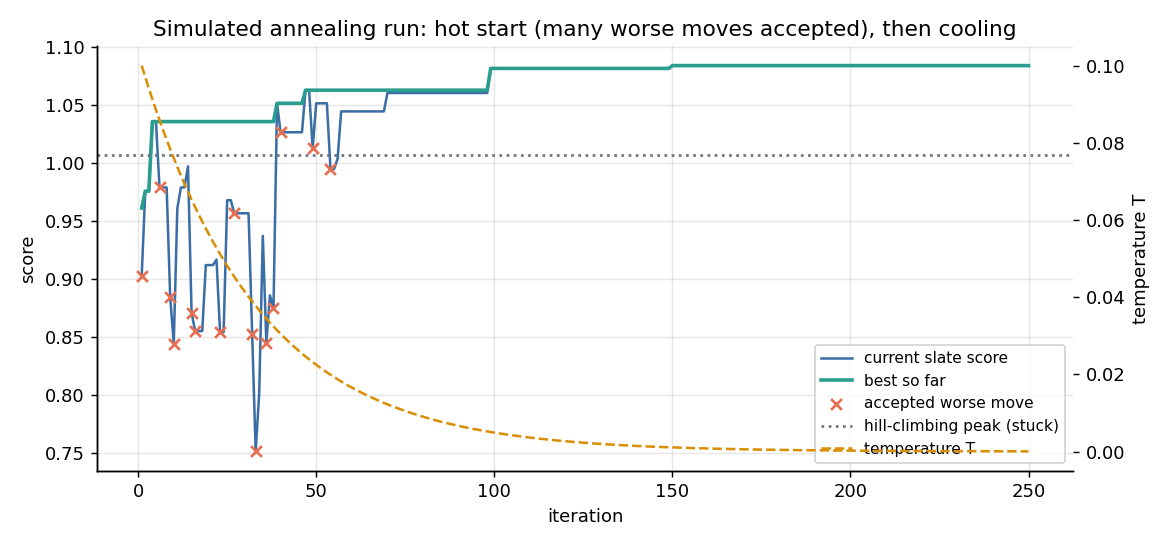

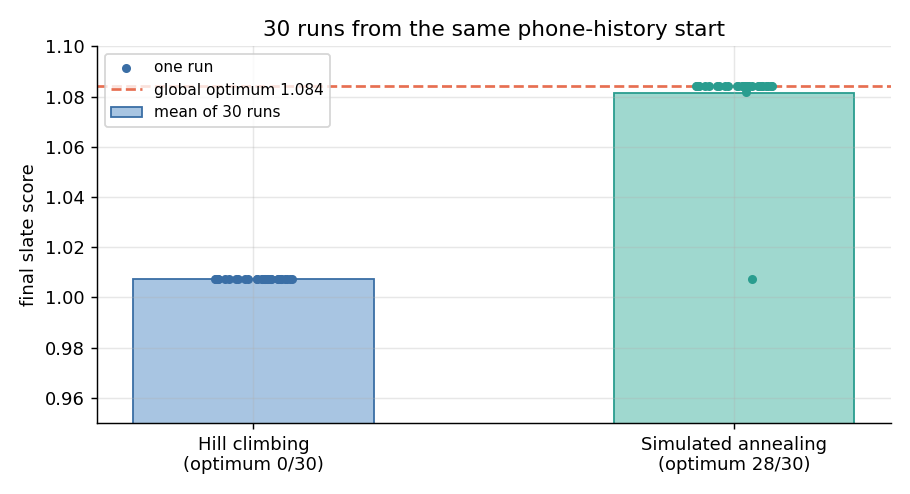

In [2]:
from IPython.display import Image, display
import glob
for p in sorted(glob.glob('images/q05_chart*.png')):
    display(Image(p))